In [1]:
!pip install nflreadpy pandas matplotlib seaborn pyarrow

In [2]:
import nflreadpy as nfl
pbp = nfl.load_pbp([2025]).to_pandas()
print(pbp.shape)

(48771, 372)


In [3]:
import sys
print(sys.version)
print(sys.executable)

3.13.18 | packaged by Anaconda, Inc. | (main, Oct 27 2026, 00:49:14) [Clang 20.1.8 ]
/opt/anaconda3/envs/nfl/bin/python


In [4]:
%pip install nflreadpy pandas matplotlib seaborn pyarrow

Note: you may need to restart the kernel to use updated packages.


In [5]:
import nflreadpy as nfl
pbp = nfl.load_pbp([2025]).to_pandas()
print(pbp.shape)

(48771, 372)


In [6]:
pbp[["posteam", "defteam", "week", "down", "ydstogo", "play_type", "yards_gained", "epa", "success"]].head(10)

,posteam,defteam,week,down,ydstogo,play_type,yards_gained,epa,success
0,NaN,NaN,1,NaN,0.0,NaN,NaN,-0.000000,0.0
1,ARI,NO,1,NaN,0.0,kickoff,0.0,-0.497133,0.0
2,ARI,NO,1,1.0,10.0,run,3.0,-0.157654,0.0
3,ARI,NO,1,2.0,7.0,pass,11.0,0.994526,1.0
4,ARI,NO,1,1.0,10.0,pass,-11.0,-1.262290,0.0
5,ARI,NO,1,2.0,21.0,run,-2.0,-0.958391,0.0
6,ARI,NO,1,3.0,23.0,run,1.0,-0.630602,0.0
7,ARI,NO,1,4.0,22.0,punt,0.0,0.443674,1.0
8,NO,ARI,1,1.0,10.0,run,3.0,-0.149376,0.0
9,NO,ARI,1,2.0,7.0,pass,0.0,-0.602408,0.0


In [7]:
runs = pbp[
    (pbp["season_type"] == "REG") &
    (pbp["rush_attempt"] == 1) &
    (pbp["qb_scramble"] == 0) &
    (pbp["posteam"].notna())
].copy()

print(runs.shape)

(13544, 372)


In [8]:
runs["epa"].describe()

count    13544.000000
mean        -0.048709
std          0.827589
min         -9.281452
25%         -0.425586
50%         -0.134251
75%          0.326683
max          5.620527
Name: epa, dtype: float64

In [9]:
team_runs = (
    runs.groupby("posteam")
    .agg(
        carries=("epa", "size"),
        epa_per_rush=("epa", "mean"),
        success_rate=("success", "mean"),
        yards_per_carry=("yards_gained", "mean"),
    )
    .reset_index()
    .sort_values("epa_per_rush", ascending=False)
)

team_runs.head(10)

,posteam,carries,epa_per_rush,success_rate,yards_per_carry
13,IND,418,0.043934,0.433014,4.389952
2,BAL,470,0.033812,0.410638,5.019149
3,BUF,497,0.029900,0.454728,4.577465
5,CHI,463,0.014987,0.468683,4.514039
6,CIN,368,0.014281,0.440217,4.119565
26,PIT,394,0.002596,0.431472,4.276650
16,LA,458,0.000949,0.475983,4.650655
8,DAL,436,-0.020151,0.422018,4.444954
19,MIA,417,-0.020863,0.407674,4.738609
23,NYG,461,-0.028815,0.394794,3.915401


In [12]:
import os
print(os.getcwd())
print(os.listdir())

/Users/alexandraestevez/Documents/GitHub/nfl-run-game-analysis/notebooks
['images', 'team_rushing_efficieny.ipynb', '.ipynb_checkpoints']


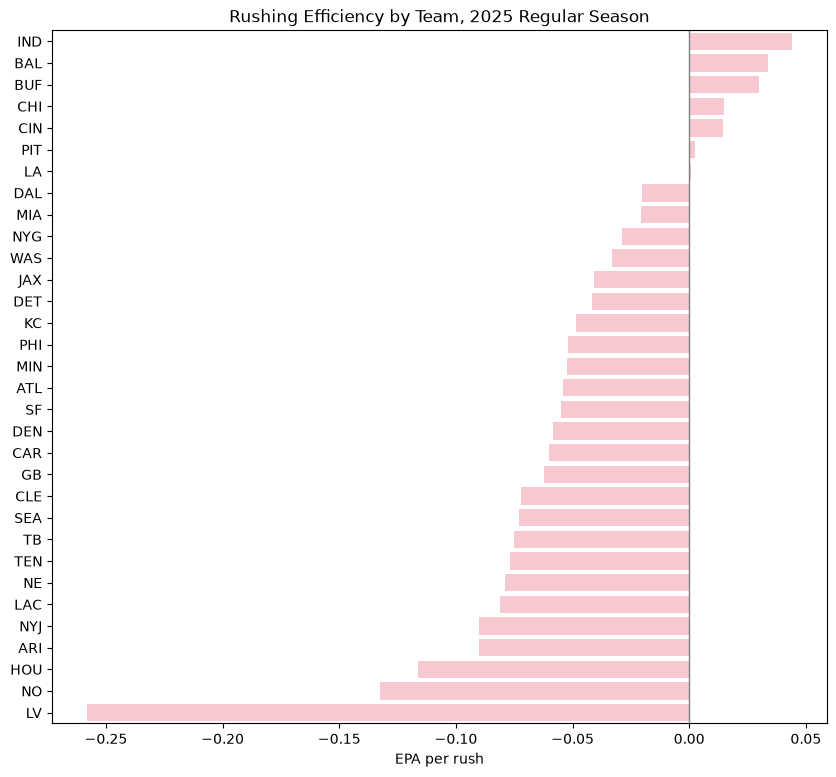

In [14]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 9))
sns.barplot(data=team_runs, y="posteam", x="epa_per_rush", color="pink")
plt.axvline(0, color="gray", linewidth=1)
plt.title("Rushing Efficiency by Team, 2025 Regular Season")
plt.xlabel("EPA per rush")
plt.ylabel("")

os.makedirs("images", exist_ok=True)
plt.savefig("images/rush_epa_by_team.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
teams_alpha = sorted(team_runs["posteam"].unique())
team_runs["team_id"] = team_runs["posteam"].map({t: i for i, t in enumerate(teams_alpha)})
team_runs["label"] = team_runs["team_id"].astype(str) + " " + team_runs["posteam"]

team_runs = team_runs.sort_values("epa_per_rush", ascending=False)
team_runs[["label", "carries", "epa_per_rush"]].head(10)

,label,carries,epa_per_rush
13,13 IND,418,0.043934
2,2 BAL,470,0.033812
3,3 BUF,497,0.029900
5,5 CHI,463,0.014987
6,6 CIN,368,0.014281
26,26 PIT,394,0.002596
16,16 LA,458,0.000949
8,8 DAL,436,-0.020151
19,19 MIA,417,-0.020863
23,23 NYG,461,-0.028815


## Does rushing efficiency predict winning?

In [ ]:
import pandas as pd

sched = nfl.load_schedules([2025]).to_pandas()
sched = sched[(sched["game_type"] == "REG") & sched["result"].notna()]

home = sched[["home_team", "home_score", "away_score"]].set_axis(["team", "pf", "pa"], axis=1)
away = sched[["away_team", "away_score", "home_score"]].set_axis(["team", "pf", "pa"], axis=1)
games = pd.concat([home, away])

games["win"] = (games["pf"] > games["pa"]).astype(float)
games.loc[games["pf"] == games["pa"], "win"] = 0.5   # ties count as half a win

records = games.groupby("team").agg(wins=("win", "sum"), games=("win", "size")).reset_index()
records["win_pct"] = records["wins"] / records["games"]
records.sort_values("win_pct", ascending=False).head(10)

In [ ]:
merged = team_runs.merge(records, left_on="posteam", right_on="team")
print(len(merged))

In [ ]:
print(merged[["epa_per_rush", "win_pct"]].corr())

plt.figure(figsize=(9, 7))
sns.regplot(data=merged, x="epa_per_rush", y="win_pct", color="steelblue")
for _, r in merged.iterrows():
    plt.text(r["epa_per_rush"], r["win_pct"], r["posteam"], fontsize=8)
plt.title("Rushing Efficiency vs. Win % (2025)")
plt.xlabel("EPA per rush")
plt.ylabel("Win %")

plt.savefig("images/rush_epa_vs_wins.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
merged_no_lv = merged[merged["posteam"] != "LV"]
print(merged_no_lv[["epa_per_rush", "win_pct"]].corr())

In [ ]:
plt.text(r["epa_per_rush"] + 0.002, r["win_pct"] + 0.008, r["posteam"], fontsize=8)

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

merged_no_lv = merged[merged["posteam"] != "LV"]

print("With LV:   ", round(merged["epa_per_rush"].corr(merged["win_pct"]), 3))
print("Without LV:", round(merged_no_lv["epa_per_rush"].corr(merged_no_lv["win_pct"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, data, title in [(axes[0], merged, "All 32 teams"), (axes[1], merged_no_lv, "Without LV")]:
    sns.regplot(data=data, x="epa_per_rush", y="win_pct", color="steelblue", ax=ax)
    for _, r in data.iterrows():
        ax.text(r["epa_per_rush"] + 0.002, r["win_pct"] + 0.008, r["posteam"], fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("EPA per rush")
    ax.set_ylabel("Win %")

fig.suptitle("Rushing Efficiency vs. Win % (2025)")
os.makedirs("images", exist_ok=True)
plt.savefig("images/rush_epa_vs_wins_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
passes = pbp[(pbp["season_type"] == "REG") & (pbp["pass"] == 1) & pbp["posteam"].notna()]
team_pass = passes.groupby("posteam").agg(epa_per_pass=("epa", "mean")).reset_index()

merged2 = merged.merge(team_pass, on="posteam")
print(merged2[["epa_per_rush", "epa_per_pass", "win_pct"]].corr().round(3))

In [ ]:
seasons = [2022, 2023, 2024, 2025]
pbp_all = nfl.load_pbp(seasons).to_pandas()
reg = pbp_all[(pbp_all["season_type"] == "REG") & pbp_all["posteam"].notna()]

rush = (reg[(reg["rush_attempt"] == 1) & (reg["qb_scramble"] == 0)]
        .groupby(["season", "posteam"])
        .agg(epa_per_rush=("epa", "mean"), rushes=("epa", "size"))
        .reset_index())

pas = (reg[reg["pass"] == 1]
       .groupby(["season", "posteam"])
       .agg(epa_per_pass=("epa", "mean"))
       .reset_index())

sched = nfl.load_schedules(seasons).to_pandas()
sched = sched[(sched["game_type"] == "REG") & sched["result"].notna()]
home = sched[["season", "home_team", "home_score", "away_score"]].set_axis(["season", "team", "pf", "pa"], axis=1)
away = sched[["season", "away_team", "away_score", "home_score"]].set_axis(["season", "team", "pf", "pa"], axis=1)
games = pd.concat([home, away])
games["win"] = (games["pf"] > games["pa"]).astype(float)
games.loc[games["pf"] == games["pa"], "win"] = 0.5
rec = games.groupby(["season", "team"]).agg(win_pct=("win", "mean")).reset_index()

multi = (rush.merge(pas, on=["season", "posteam"])
             .merge(rec, left_on=["season", "posteam"], right_on=["season", "team"]))

print(len(multi))
print(multi[["epa_per_rush", "epa_per_pass", "win_pct"]].corr().round(3))

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Does the pattern hold in each individual season?
for s, g in multi.groupby("season"):
    print(s,
          "rush:", round(g["epa_per_rush"].corr(g["win_pct"]), 3),
          "pass:", round(g["epa_per_pass"].corr(g["win_pct"]), 3))

# 2. Chart: both relationships across all 128 team-seasons
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, col, title in [(axes[0], "epa_per_rush", "Rushing efficiency"),
                       (axes[1], "epa_per_pass", "Passing efficiency")]:
    sns.regplot(data=multi, x=col, y="win_pct", color="steelblue", ax=ax,
                scatter_kws={"alpha": 0.6})
    r = multi[col].corr(multi["win_pct"])
    ax.set_title(f"{title} (r = {r:.2f})")
    ax.set_xlabel("EPA per play")
    ax.set_ylabel("Win %")

fig.suptitle("EPA vs. Win %, 2022-2025 (128 team-seasons)")
os.makedirs("images", exist_ok=True)
plt.savefig("images/epa_vs_wins_multi_season.png", dpi=200, bbox_inches="tight")
plt.show()